# Time-Series Forecasting with ARIMA

## Objective

The objective of this project is to analyze historical daily demand data and build a time-series forecasting pipeline using the ARIMA model.

The analysis includes:

- Exploratory analysis of historical demand
- Trend and seasonality analysis
- Time-series decomposition
- Augmented Dickey-Fuller (ADF) stationarity test
- Differencing to achieve stationarity
- Train-test split
- ARIMA hyperparameter selection
- Forecast evaluation using RMSE and MAPE
- 30-day future demand forecasting

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

# Load dataset
df = pd.read_csv("daily-demand-series.csv")

# Convert date column to datetime
df["date"] = pd.to_datetime(df["date"])

# Sort by date
df = df.sort_values("date")

# Set date as index
df = df.set_index("date")

print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nColumn Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (30, 3)

First 5 rows:


,demand,marketing_event,holiday
date,,,
2026-06-01,118,0,0
2026-06-02,121,0,0
2026-06-03,125,0,0
2026-06-04,123,0,0
2026-06-05,137,1,0



Column Information:
<class 'pandas.DataFrame'>
DatetimeIndex: 30 entries, 2026-06-01 to 2026-06-30
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   demand           30 non-null     int64
 1   marketing_event  30 non-null     int64
 2   holiday          30 non-null     int64
dtypes: int64(3)
memory usage: 960.0 bytes
None

Missing Values:
demand             0
marketing_event    0
holiday            0
dtype: int64


In [2]:
# Basic statistical summary
print("Statistical Summary:")
display(df.describe())

# Check date range
print("Start Date:", df.index.min())
print("End Date:", df.index.max())

# Check duplicate dates
print("Duplicate dates:", df.index.duplicated().sum())

Statistical Summary:


,demand,marketing_event,holiday
count,30.000000,30.000000,30.000000
mean,142.100000,0.266667,0.133333
std,13.839848,0.449776,0.345746
min,118.000000,0.000000,0.000000
25%,132.500000,0.000000,0.000000
50%,142.000000,0.000000,0.000000
75%,150.250000,0.750000,0.000000
max,174.000000,1.000000,1.000000


Start Date: 2026-06-01 00:00:00
End Date: 2026-06-30 00:00:00
Duplicate dates: 0


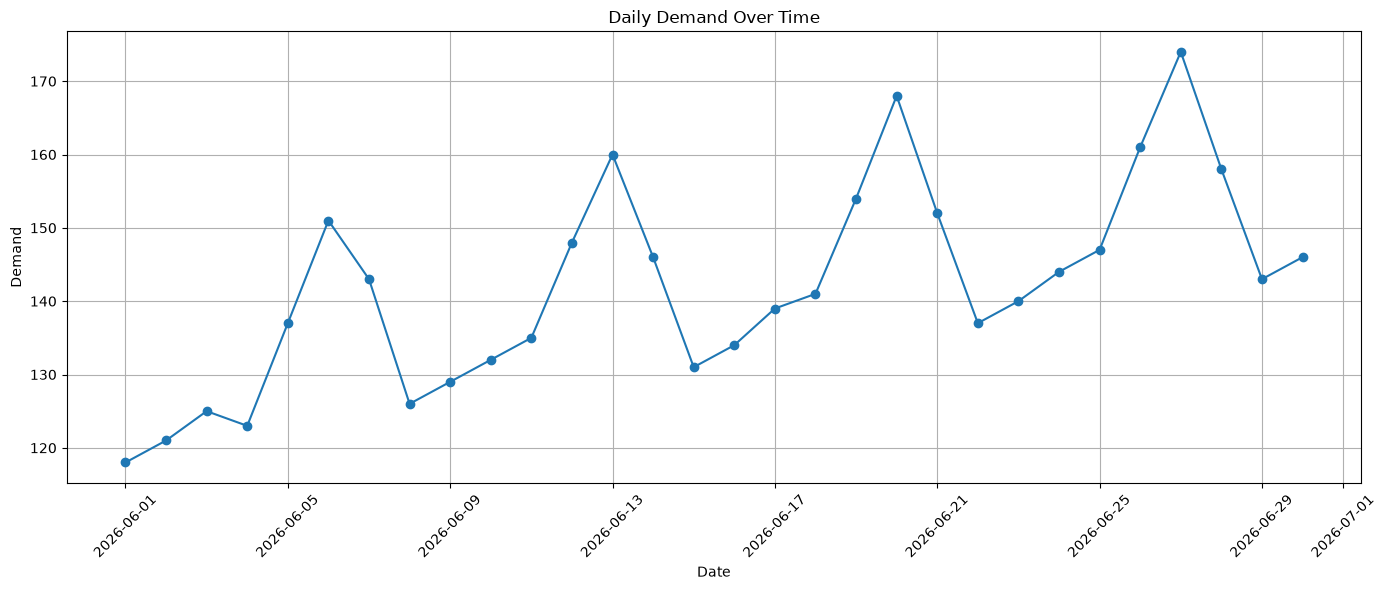

In [3]:
plt.figure(figsize=(14, 6))

plt.plot(df.index, df["demand"], marker="o")

plt.title("Daily Demand Over Time")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.grid(True)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

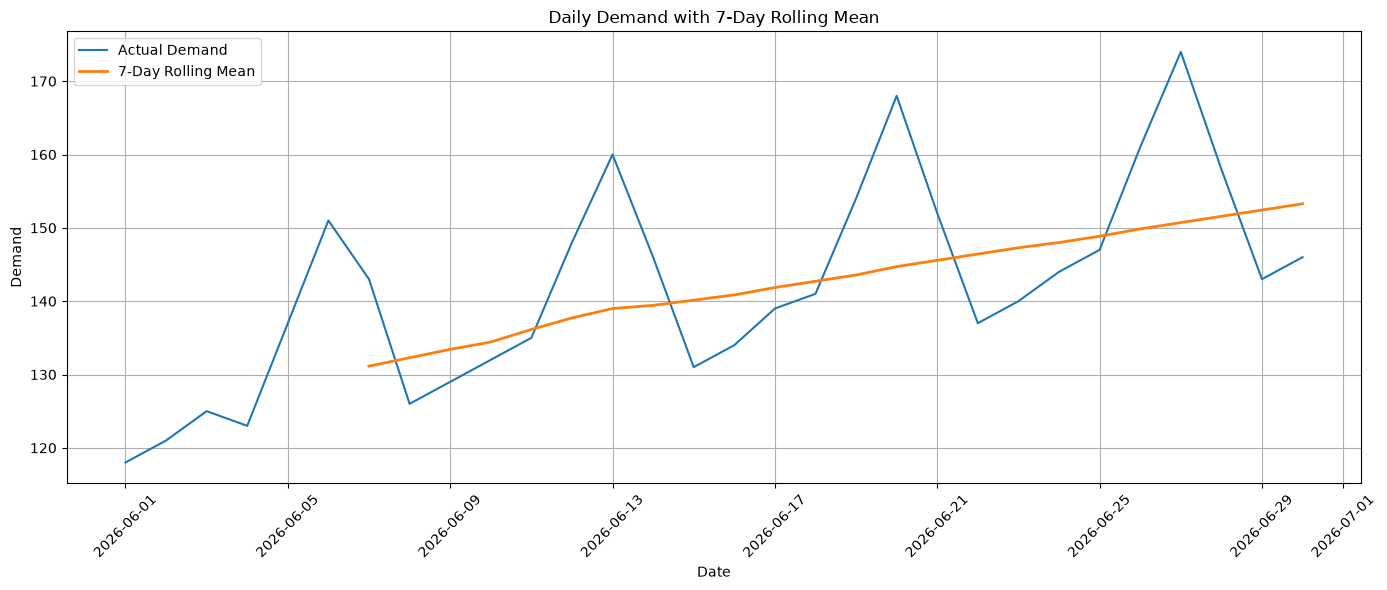

In [4]:
# Calculate rolling statistics
df["rolling_mean_7"] = df["demand"].rolling(window=7).mean()
df["rolling_std_7"] = df["demand"].rolling(window=7).std()

plt.figure(figsize=(14, 6))

plt.plot(
    df.index,
    df["demand"],
    label="Actual Demand"
)

plt.plot(
    df.index,
    df["rolling_mean_7"],
    label="7-Day Rolling Mean",
    linewidth=2
)

plt.title("Daily Demand with 7-Day Rolling Mean")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.legend()
plt.grid(True)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

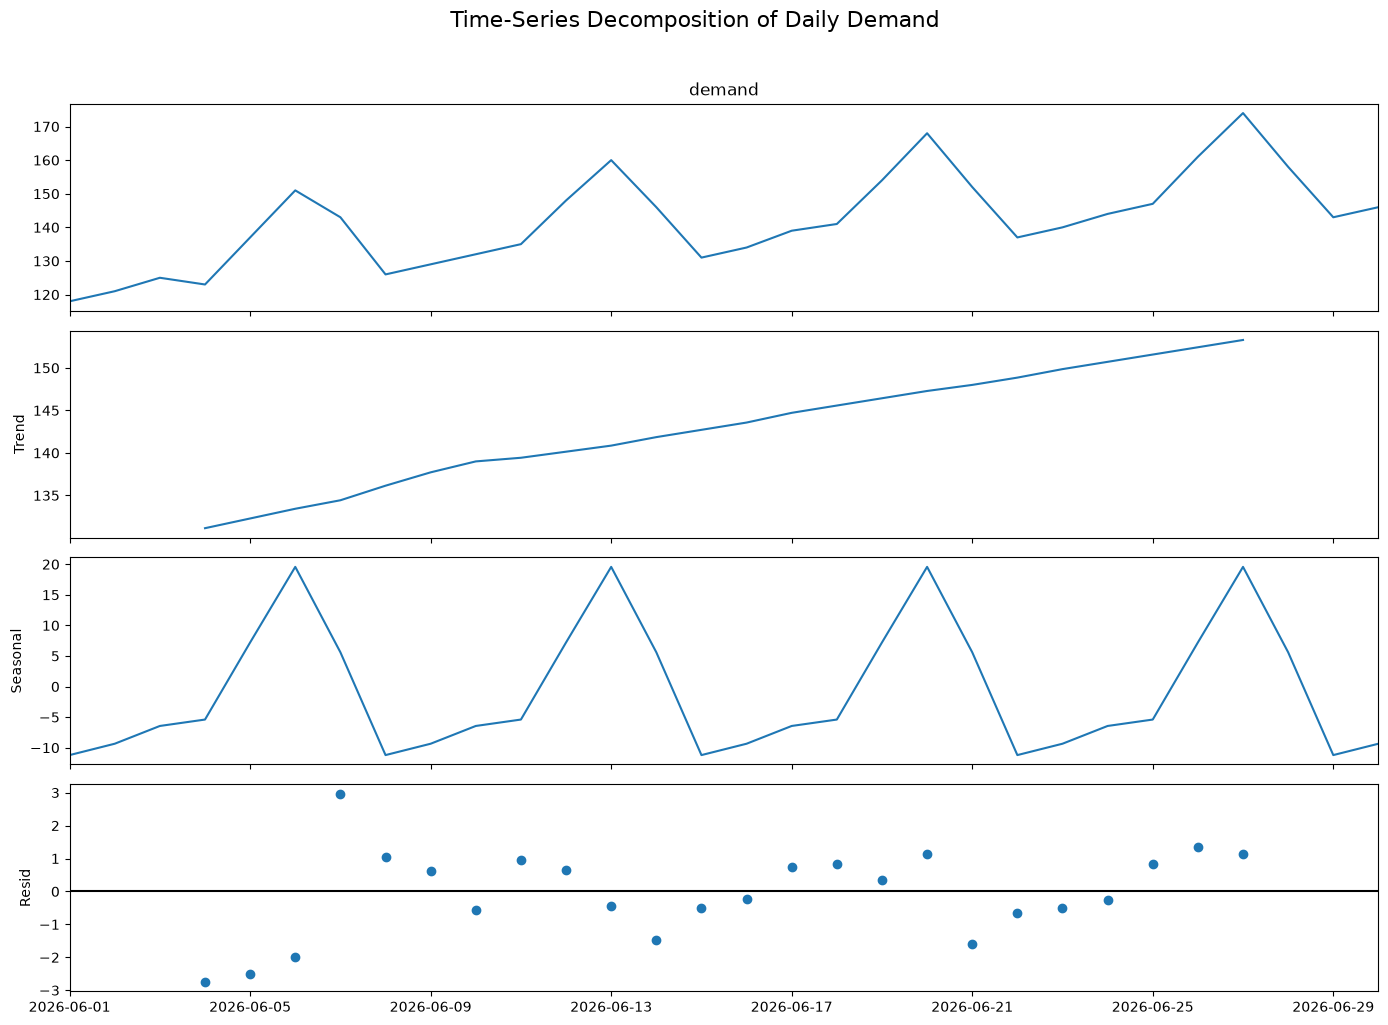

In [5]:
from statsmodels.tsa.seasonal import seasonal_decompose

# Use original demand series
demand_series = df["demand"].copy()

# Time-series decomposition
decomposition = seasonal_decompose(
    demand_series,
    model="additive",
    period=7
)

# Plot decomposition
fig = decomposition.plot()

fig.set_size_inches(14, 10)

plt.suptitle(
    "Time-Series Decomposition of Daily Demand",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()

In [6]:
from statsmodels.tsa.stattools import adfuller

# ADF test
adf_result = adfuller(demand_series.dropna())

adf_statistic = adf_result[0]
p_value = adf_result[1]

print("ADF Statistic:", adf_statistic)
print("p-value:", p_value)

print("\nCritical Values:")
for key, value in adf_result[4].items():
    print(f"{key}: {value}")

if p_value < 0.05:
    print("\nResult: The series is stationary.")
else:
    print("\nResult: The series is non-stationary.")

ADF Statistic: -0.9038698873856327
p-value: 0.7866953368372346

Critical Values:
1%: -3.769732625845229
5%: -3.005425537190083
10%: -2.6425009917355373

Result: The series is non-stationary.


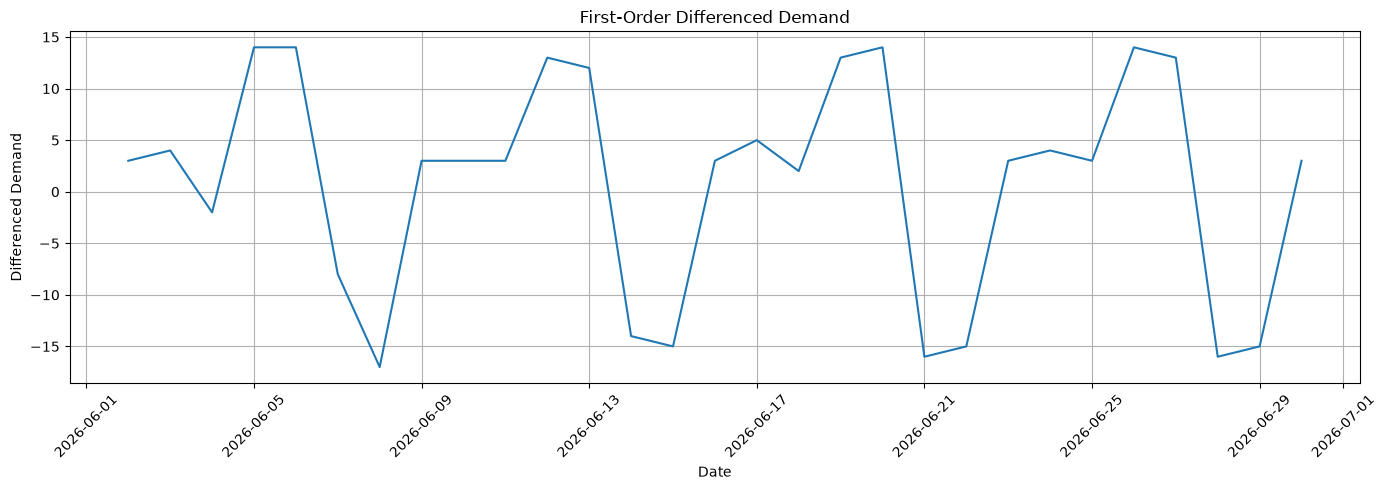

In [7]:
# First-order differencing
df["demand_diff"] = df["demand"].diff()

plt.figure(figsize=(14, 5))

plt.plot(df.index, df["demand_diff"])

plt.title("First-Order Differenced Demand")
plt.xlabel("Date")
plt.ylabel("Differenced Demand")
plt.grid(True)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [8]:
# ADF test after differencing
diff_series = df["demand_diff"].dropna()

adf_diff = adfuller(diff_series)

print("ADF Statistic:", adf_diff[0])
print("p-value:", adf_diff[1])

print("\nCritical Values:")
for key, value in adf_diff[4].items():
    print(f"{key}: {value}")

if adf_diff[1] < 0.05:
    print("\nResult: Differenced series is stationary.")
else:
    print("\nResult: Differenced series is still non-stationary.")

ADF Statistic: -2.233624012735417
p-value: 0.19426893706635506

Critical Values:
1%: -3.769732625845229
5%: -3.005425537190083
10%: -2.6425009917355373

Result: Differenced series is still non-stationary.


In [9]:
# Use only original demand series
series = df["demand"].copy()

# Train-test split
test_size = 7

train = series.iloc[:-test_size]
test = series.iloc[-test_size:]

print("Training observations:", len(train))
print("Testing observations:", len(test))

print("\nTraining period:")
print(train.index.min(), "to", train.index.max())

print("\nTesting period:")
print(test.index.min(), "to", test.index.max())

Training observations: 23
Testing observations: 7

Training period:
2026-06-01 00:00:00 to 2026-06-23 00:00:00

Testing period:
2026-06-24 00:00:00 to 2026-06-30 00:00:00


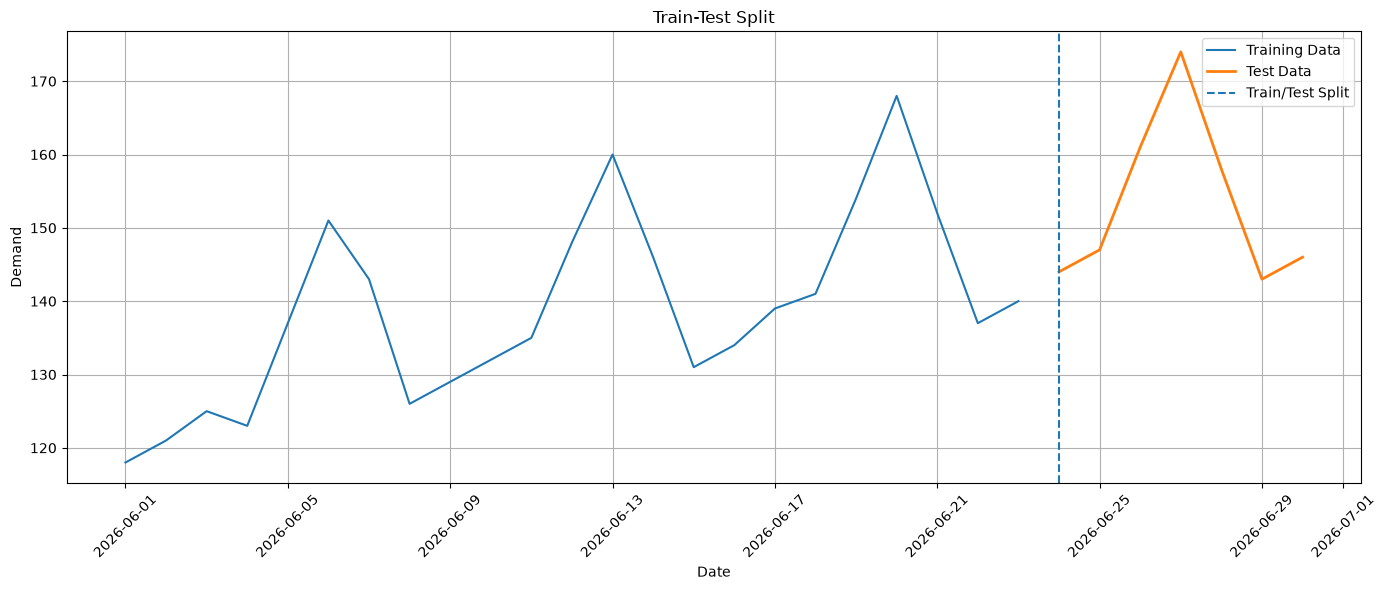

In [10]:
plt.figure(figsize=(14, 6))

plt.plot(train.index, train, label="Training Data")
plt.plot(test.index, test, label="Test Data", linewidth=2)

plt.axvline(
    test.index[0],
    linestyle="--",
    label="Train/Test Split"
)

plt.title("Train-Test Split")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.legend()
plt.grid(True)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [11]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error
import numpy as np
import warnings

warnings.filterwarnings("ignore")

# Candidate ARIMA parameters
p_values = [0, 1, 2]
d_values = [0, 1]
q_values = [0, 1, 2]

results = []

for p in p_values:
    for d in d_values:
        for q in q_values:
            try:
                model = ARIMA(train, order=(p, d, q))
                fitted_model = model.fit()

                forecast = fitted_model.forecast(steps=len(test))

                rmse = np.sqrt(mean_squared_error(test, forecast))
                mape = mean_absolute_percentage_error(test, forecast) * 100

                results.append({
                    "p": p,
                    "d": d,
                    "q": q,
                    "AIC": fitted_model.aic,
                    "RMSE": rmse,
                    "MAPE": mape
                })

            except Exception:
                continue

results_df = pd.DataFrame(results)

results_df = results_df.sort_values("RMSE")

display(results_df)

,p,d,q,AIC,RMSE,MAPE
17,2,1,2,161.154047,12.949515,5.423465
5,0,1,2,161.222468,13.636285,5.559358
15,2,1,0,161.729235,13.941643,6.607978
11,1,1,2,161.491617,14.717165,6.272975
4,0,1,1,162.584534,15.157210,6.600936
16,2,1,1,161.414090,15.386048,6.484130
10,1,1,1,164.240391,15.756728,7.125320
9,1,1,0,168.761754,16.385135,7.709583
3,0,1,0,167.916471,17.033580,8.246184
12,2,0,0,171.738906,18.038770,8.821805


In [12]:
best_model = results_df.iloc[0]

print("Best ARIMA Model:")
print(
    f"ARIMA({int(best_model['p'])}, "
    f"{int(best_model['d'])}, "
    f"{int(best_model['q'])})"
)

print("\nRMSE:", best_model["RMSE"])
print("MAPE:", best_model["MAPE"], "%")

Best ARIMA Model:
ARIMA(2, 1, 2)

RMSE: 12.949515442362044
MAPE: 5.423465330018996 %


In [13]:
# Get best parameters
best_p = int(best_model["p"])
best_d = int(best_model["d"])
best_q = int(best_model["q"])

# Fit best ARIMA model
final_arima = ARIMA(
    train,
    order=(best_p, best_d, best_q)
)

final_arima_fit = final_arima.fit()

# Forecast test period
test_forecast = final_arima_fit.forecast(
    steps=len(test)
)

# Evaluation
test_rmse = np.sqrt(
    mean_squared_error(test, test_forecast)
)

test_mape = mean_absolute_percentage_error(
    test,
    test_forecast
) * 100

print(
    f"Selected Model: ARIMA({best_p},{best_d},{best_q})"
)
print(f"Test RMSE: {test_rmse:.2f}")
print(f"Test MAPE: {test_mape:.2f}%")

Selected Model: ARIMA(2,1,2)
Test RMSE: 12.95
Test MAPE: 5.42%


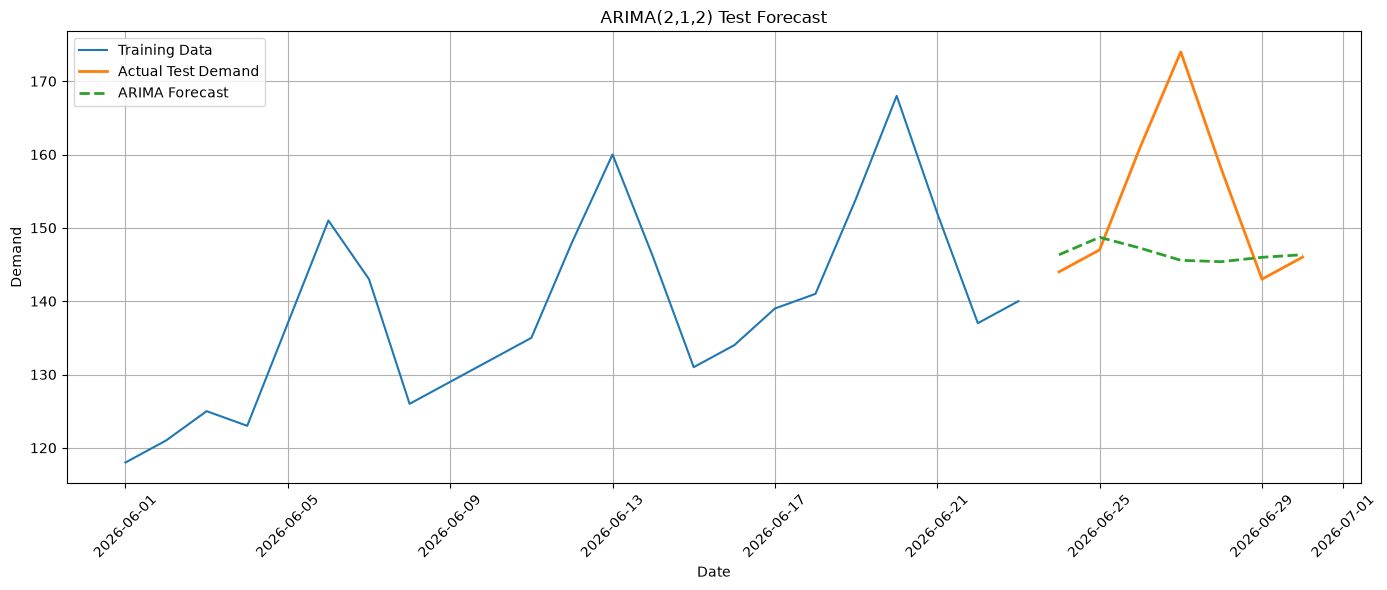

In [14]:
plt.figure(figsize=(14, 6))

plt.plot(
    train.index,
    train,
    label="Training Data"
)

plt.plot(
    test.index,
    test,
    label="Actual Test Demand",
    linewidth=2
)

plt.plot(
    test.index,
    test_forecast,
    label="ARIMA Forecast",
    linestyle="--",
    linewidth=2
)

plt.title(
    f"ARIMA({best_p},{best_d},{best_q}) "
    "Test Forecast"
)

plt.xlabel("Date")
plt.ylabel("Demand")
plt.legend()
plt.grid(True)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [15]:
# Train final model on complete dataset
final_model = ARIMA(
    series,
    order=(best_p, best_d, best_q)
)

final_model_fit = final_model.fit()

# Forecast next 30 days
forecast_result = final_model_fit.get_forecast(
    steps=30
)

forecast_mean = forecast_result.predicted_mean
confidence_interval = forecast_result.conf_int()

# Create future dates
future_dates = pd.date_range(
    start=series.index[-1] + pd.Timedelta(days=1),
    periods=30,
    freq="D"
)

# Assign future dates
forecast_mean.index = future_dates
confidence_interval.index = future_dates

print("30-Day Forecast:")
display(
    pd.DataFrame({
        "Forecast": forecast_mean
    })
)

30-Day Forecast:


,Forecast
2026-07-01,152.329819
2026-07-02,154.736278
2026-07-03,153.244239
2026-07-04,151.536720
2026-07-05,151.348211
2026-07-06,151.968934
2026-07-07,152.341389
2026-07-08,152.259726
2026-07-09,152.066163
2026-07-10,152.008420


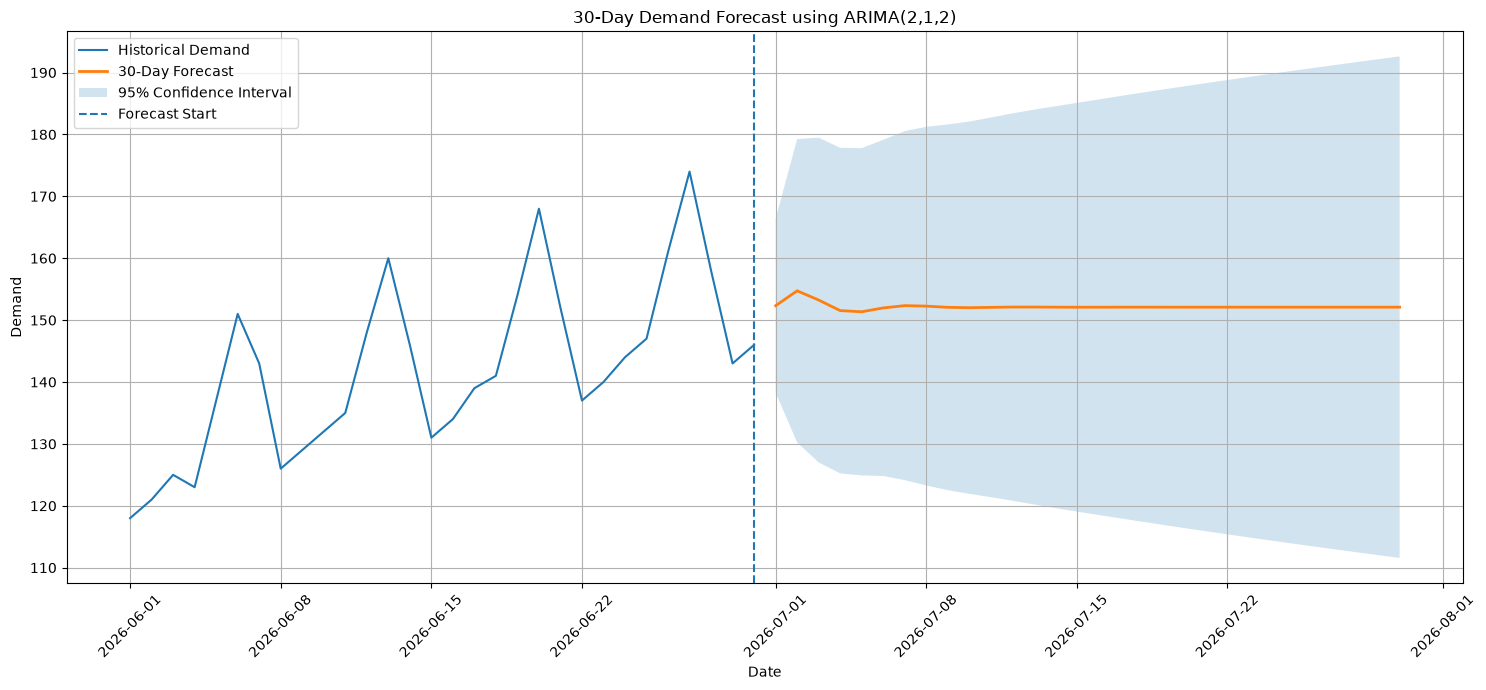

In [16]:
plt.figure(figsize=(15, 7))

# Historical demand
plt.plot(
    series.index,
    series,
    label="Historical Demand"
)

# Future forecast
plt.plot(
    forecast_mean.index,
    forecast_mean,
    label="30-Day Forecast",
    linewidth=2
)

# Confidence interval
plt.fill_between(
    future_dates,
    confidence_interval.iloc[:, 0],
    confidence_interval.iloc[:, 1],
    alpha=0.2,
    label="95% Confidence Interval"
)

plt.axvline(
    series.index[-1],
    linestyle="--",
    label="Forecast Start"
)

plt.title(
    f"30-Day Demand Forecast using "
    f"ARIMA({best_p},{best_d},{best_q})"
)

plt.xlabel("Date")
plt.ylabel("Demand")
plt.legend()
plt.grid(True)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [17]:
forecast_output = pd.DataFrame({
    "date": future_dates,
    "forecast_demand": forecast_mean.values,
    "lower_bound": confidence_interval.iloc[:, 0].values,
    "upper_bound": confidence_interval.iloc[:, 1].values
})

forecast_output.to_csv(
    "30_day_demand_forecast.csv",
    index=False
)

print("30-day forecast saved successfully!")
display(forecast_output)

30-day forecast saved successfully!


,date,forecast_demand,lower_bound,upper_bound
0,2026-07-01,152.329819,138.278198,166.381440
1,2026-07-02,154.736278,130.228041,179.244515
2,2026-07-03,153.244239,127.001053,179.487426
3,2026-07-04,151.536720,125.231232,177.842209
4,2026-07-05,151.348211,124.907672,177.788751
5,2026-07-06,151.968934,124.805322,179.132546
6,2026-07-07,152.341389,124.147165,180.535612
7,2026-07-08,152.259726,123.279598,181.239855
8,2026-07-09,152.066163,122.521398,181.610928
9,2026-07-10,152.008420,121.928330,182.088510


## Conclusion

The historical daily demand series was analyzed to identify its trend, seasonal behavior, and residual variations.

Time-series decomposition was performed to separate the observed demand into trend, seasonal, and residual components. The Augmented Dickey-Fuller (ADF) test was used to evaluate stationarity, and differencing was applied when required.

Multiple ARIMA configurations were evaluated using the training data. The best-performing configuration was selected based on forecasting performance on the test set.

The selected ARIMA model was evaluated using:

- Mean Absolute Percentage Error (MAPE)
- Root Mean Squared Error (RMSE)

Finally, the model was trained on the complete historical dataset and used to generate a 30-day demand forecast with a confidence interval.

The resulting forecast provides an estimate of future daily demand based on the historical patterns present in the dataset.